# Option pricing demo

A quick tour of the three pricers in this repo: Black-Scholes, a CRR binomial tree and Monte Carlo. I price the same option with all of them so the numbers can be compared directly.

Everything runs off the parameters in the next cell. Change them there and rerun the notebook.

In [1]:
import os, sys
sys.path.append(os.path.dirname(os.getcwd()))  # lets us import models/ from notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from models import black_scholes as bs
from models import binomial_tree as bt
from models import monte_carlo as mc

plt.rcParams["figure.figsize"] = (8, 4.5)

# play with these
S = 102.5      # spot
K = 105        # strike
T = 0.75       # years
r = 0.035
sigma = 0.27

## Black-Scholes

Closed-form price for a call and a put, then the greeks of the call.

In [2]:
call = bs.price(S, K, T, r, sigma, "call")
put = bs.price(S, K, T, r, sigma, "put")
print("call", round(call, 4))
print("put", round(put, 4))

g = bs.greeks(S, K, T, r, sigma, "call")
for name, val in g.items():
    print(name, round(val, 5))

call 9.6402
put 9.4198
delta 0.55018
gamma 0.01651
vega 0.35133
theta -0.02181
rho 0.35065


Quick check on delta: bump the spot up and down a bit, reprice, and compare with the analytical value. They should be close but not identical, finite differences always leave a small error.

In [3]:
h = 0.01
fd_delta = (bs.price(S + h, K, T, r, sigma, "call") - bs.price(S - h, K, T, r, sigma, "call")) / (2 * h)
print(fd_delta, g["delta"], abs(fd_delta - g["delta"]))

0.5501810283902842 0.5501810325232891 4.133004938289275e-09


Put-call parity. This one is zero up to floating point by construction, so it only really catches typos in the formulas.

In [4]:
par = bs.put_call_parity_check(S, K, T, r, sigma)
print(par["lhs"], par["rhs"], par["error"])

0.22038869041293907 0.22038869041294618 7.105427357601002e-15


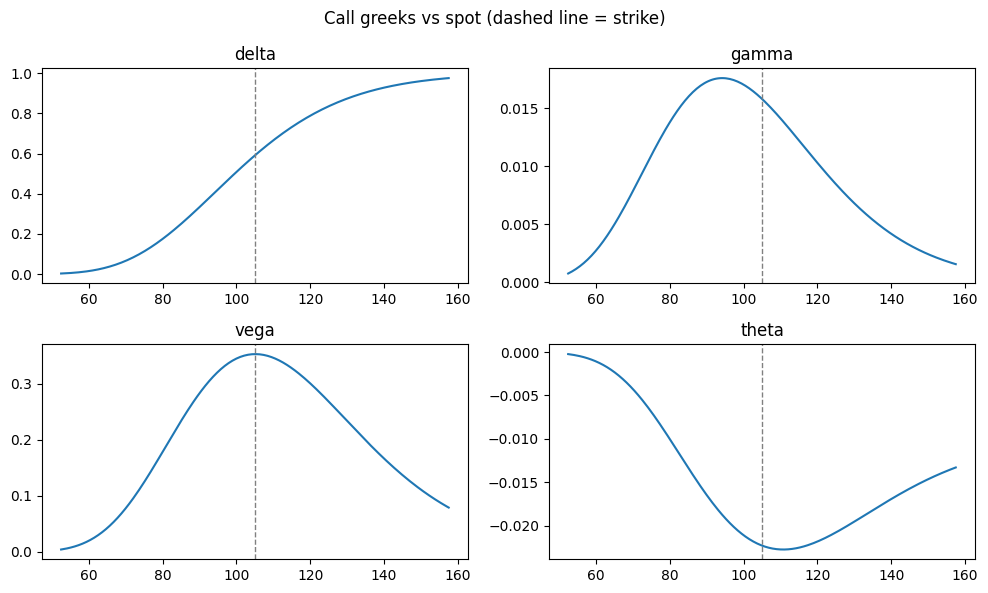

In [5]:
spots = np.linspace(0.5 * K, 1.5 * K, 200)
gk = [bs.greeks(s, K, T, r, sigma, "call") for s in spots]

fig, axes = plt.subplots(2, 2, figsize=(10, 6))
for ax, name in zip(axes.flat, ["delta", "gamma", "vega", "theta"]):
    ax.plot(spots, [x[name] for x in gk])
    ax.axvline(K, color="gray", ls="--", lw=1)
    ax.set_title(name)
fig.suptitle("Call greeks vs spot (dashed line = strike)")
fig.tight_layout()
plt.show()

## Binomial tree

European first, to see how close 200 steps gets to Black-Scholes.

In [6]:
for kind in ("call", "put"):
    tree = bt.price(S, K, T, r, sigma, 200, kind, "european")
    exact = bs.price(S, K, T, r, sigma, kind)
    print(kind, round(tree, 4), round(exact, 4), round(tree - exact, 4))

call 9.6467 9.6402 0.0066
put 9.4263 9.4198 0.0066


Now American vs European. The call shouldn't have any early exercise premium since there are no dividends, the put should.

In [7]:
for kind in ("call", "put"):
    res = bt.early_exercise_premium(S, K, T, r, sigma, 200, kind)
    print(kind, round(res["european"], 4), round(res["american"], 4), round(res["premium"], 4))

call 9.6467 9.6467 0.0
put 9.4263 9.7273 0.301


Convergence in N. The error doesn't shrink smoothly, it jumps around depending on where the strike falls relative to the nodes at maturity. That's the well-known saw-tooth of the CRR tree.

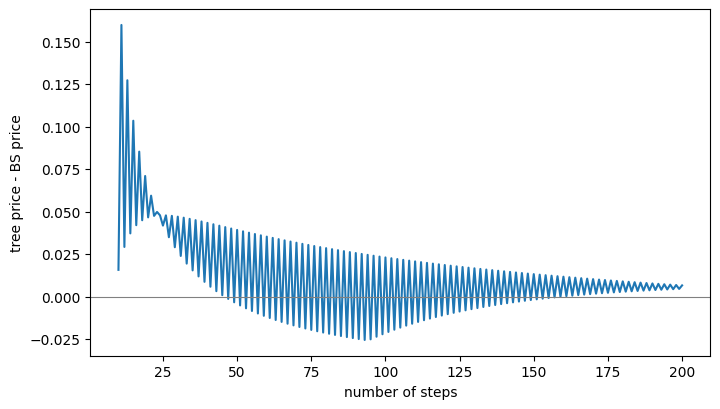

In [8]:
ref = bs.price(S, K, T, r, sigma, "call")
Ns = list(range(10, 201))
errs = [bt.price(S, K, T, r, sigma, n, "call", "european") - ref for n in Ns]

plt.plot(Ns, errs)
plt.axhline(0, color="gray", lw=0.8)
plt.xlabel("number of steps")
plt.ylabel("tree price - BS price")
plt.show()

## Monte Carlo

Price with a 95% confidence interval. The seed is fixed so the run is reproducible.

In [9]:
for kind in ("call", "put"):
    res = mc.price_with_ci(S, K, T, r, sigma, n_sim=100_000, option_type=kind, seed=1)
    exact = bs.price(S, K, T, r, sigma, kind)
    print(kind, round(res["price"], 4), (round(res["ci_lower"], 4), round(res["ci_upper"], 4)), "BS:", round(exact, 4))

call 9.5798 (9.48, 9.6796) BS: 9.6402
put 9.3837 (9.3087, 9.4587) BS: 9.4198


Here is a less trivial use of the implied vol solver. Take the noisy Monte Carlo price and invert Black-Scholes on it. We put in sigma, so we should get something near it, but not exactly.

In [10]:
mc_call = mc.price(S, K, T, r, sigma, n_sim=100_000, option_type="call", seed=1)
print(sigma, bs.implied_vol(mc_call, S, K, T, r, "call"))

0.27 0.26828275706713234


Antithetic variates vs plain sampling. This one isn't seeded, so the ratio moves around a bit from run to run (20 or 50 runs is not a lot to estimate a variance from).

In [11]:
comp = mc.antithetic_comparison(S, K, T, r, sigma, "call", n_runs=50)
print("plain std", comp["std_volatility"])
print("antithetic std", comp["anti_volatility"])
print("variance ratio", comp["variance_reduction"])

plain std 0.14456682406914445
antithetic std 0.12262697504025198
variance ratio 1.3898414191960877


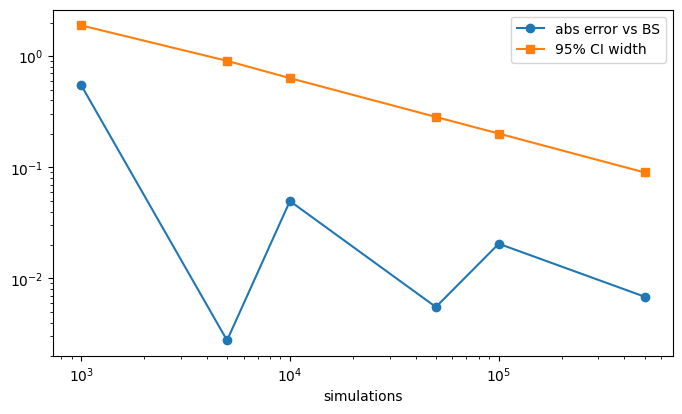

In [12]:
conv = mc.convergence_vs_bs(S, K, T, r, sigma, "call")
n = [row["n_sim"] for row in conv["convergence"]]
err = [row["error"] for row in conv["convergence"]]
width = [row["ic_width"] for row in conv["convergence"]]

plt.loglog(n, err, "o-", label="abs error vs BS")
plt.loglog(n, width, "s-", label="95% CI width")
plt.xlabel("simulations")
plt.legend()
plt.show()

## Same thing on a few different options

The first row is the option defined at the top. The others are there to see where each method struggles: short maturity and high vol, deep in the money, and so on. Edit the list however you like.

In [13]:
scenarios = [
    (S, K, T, r, sigma),
    (100, 100, 1.0, 0.05, 0.20),
    (95, 110, 0.25, 0.02, 0.35),
    (130, 100, 2.0, 0.04, 0.18),
    (80, 100, 0.5, 0.01, 0.45),
]

rows = []
for i, (s0, k, t, rate, vol) in enumerate(scenarios):
    exact = bs.price(s0, k, t, rate, vol, "call")
    tree = bt.price(s0, k, t, rate, vol, 200, "call", "european")
    sim = mc.price(s0, k, t, rate, vol, n_sim=100_000, option_type="call", seed=i)
    rows.append([s0, k, t, rate, vol, exact, tree, sim, tree - exact, sim - exact])

table = pd.DataFrame(rows, columns=["S", "K", "T", "r", "sigma", "BS", "tree", "MC", "tree err", "MC err"])
table.round(4)

,S,K,T,r,sigma,BS,tree,MC,tree err,MC err
0,102.5,105,0.75,0.035,0.27,9.6402,9.6467,9.6676,0.0066,0.0274
1,100.0,100,1.00,0.050,0.20,10.4506,10.4406,10.4014,-0.0100,-0.0492
2,95.0,110,0.25,0.020,0.35,2.1059,2.1016,2.0937,-0.0043,-0.0121
3,130.0,100,2.00,0.040,0.18,38.8349,38.8369,38.7826,0.0020,-0.0523
4,80.0,100,0.50,0.010,0.45,4.1270,4.1175,4.1191,-0.0094,-0.0079


In [14]:
import time

def timed(f, *a, **kw):
    t0 = time.perf_counter()
    out = f(*a, **kw)
    return out, (time.perf_counter() - t0) * 1000   # ms

rows = []
for kind in ("call", "put"):
    exact, t_bs = timed(bs.price, S, K, T, r, sigma, kind)
    tree, t_bt = timed(bt.price, S, K, T, r, sigma, 500, kind, "european")
    sim, t_mc = timed(mc.price, S, K, T, r, sigma, n_sim=100_000, option_type=kind, seed=3)
    rows.append([kind, "Black-Scholes", exact, 0.0, t_bs])
    rows.append([kind, "Binomial (500)", tree, tree - exact, t_bt])
    rows.append([kind, "Monte Carlo (100k)", sim, sim - exact, t_mc])

cmp_ = pd.DataFrame(rows, columns=["option", "method", "price", "error vs BS", "time (ms)"])
cmp_.round(6)

,option,method,price,error vs BS,time (ms)
0,call,Black-Scholes,9.640153,0.000000,0.3566
1,call,Binomial (500),9.640173,0.000020,2.7568
2,call,Monte Carlo (100k),9.602462,-0.037691,2.4207
3,put,Black-Scholes,9.419764,0.000000,0.3627
4,put,Binomial (500),9.419784,0.000020,2.9258
5,put,Monte Carlo (100k),9.403641,-0.016123,1.5599


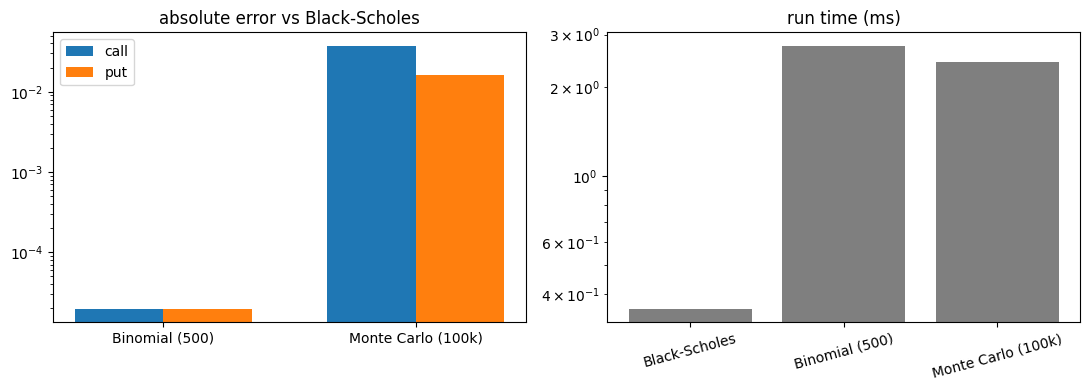

In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

methods = ["Binomial (500)", "Monte Carlo (100k)"]
x = np.arange(len(methods))
for i, kind in enumerate(("call", "put")):
    sub = cmp_[(cmp_["option"] == kind) & (cmp_["method"].isin(methods))]
    ax1.bar(x + i * 0.35, sub["error vs BS"].abs(), width=0.35, label=kind)
ax1.set_xticks(x + 0.175)
ax1.set_xticklabels(methods)
ax1.set_yscale("log")
ax1.set_title("absolute error vs Black-Scholes")
ax1.legend()

t = cmp_[cmp_["option"] == "call"]
ax2.bar(t["method"], t["time (ms)"], color="tab:gray")
ax2.set_yscale("log")
ax2.set_title("run time (ms)")
ax2.tick_params(axis="x", rotation=15)

fig.tight_layout()
plt.show()

## Vol surface

This part needs internet since it pulls a real option chain from Yahoo through yfinance. It recomputes the implied vols with our own solver, then plots the smile and the surface. If the download fails (no connection, rate limit...) it just prints the error and the notebook carries on.

In [17]:
try:
    import vol_surface

    ticker = "SPY"
    out = vol_surface.build_and_plot(ticker, option_type="call")
    print(out["data"][["expiration", "strike", "T", "mid_price", "iv"]].head(10))
    out["smile_fig"].show()
    out["surface_fig"].show()
except Exception as e:
    print("Couldn't get market data:", e)

Récupération de la chaîne d'options pour SPY...
Couldn't get market data: Too Many Requests. Rate limited. Try after a while.
